# DS 4420 Final Project
## Boston Bluebikes 2025 Hourly Demand Forecasting
### Team: Geon Chang, Miles Mu, Peisong Yuan



- Task: Predict the number of rides starting in hour t using hourly demand observed before t.
- Source: Official Bluebikes System Data (12 monthly trip-history ZIP files from January-December 2025).
- Evaluation: Chronological train (Jan-Aug), validation (Sep-Oct), test (Nov 1-Dec 30). One-step-ahead predictions with observed preceding-hour counts.

Reproduction Instructions: Download the 12 monthly ZIP files from the official Bluebikes website and place them in a Google Drive folder. Run the Setup cell, authorize Google Drive access, and enter the dataset folder path. Then select Runtime -> Run all to execute the notebook. Saved outputs reflect the team's original experiments and may vary slightly across environments; rerun the code to verify the results.

- Important scope: Systemwide departures, not individual-station inventory or total active bicycles. Models use no future ride counts, weather, or holiday indicators.

## 1. Data Acquisition and Setup
Download the 12 monthly Bluebikes trip-history ZIP files (January~December 2025) from https://bluebikes.com/system-data

Upload the ZIP files to a folder in your Google Drive, then run the Setup cell and enter the folder path. The notebook reads the CSV files directly from the ZIP archives without requiring manual extraction.

In [ ]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Enter the path containing the 12 monthly ZIP files
data_dir = Path(
    input("Enter the Bluebikes data folder path: ").strip()
)

if not data_dir.is_dir():
    raise FileNotFoundError(f"Folder not found: {data_dir}")

zip_files = sorted(data_dir.glob("*.zip"))

if len(zip_files) != 12:
    raise ValueError(
        f"Expected 12 ZIP files, found {len(zip_files)}."
    )

jan_zip = next(
    file for file in zip_files
    if file.name.startswith("202501")
)

print("Dataset folder:", data_dir)
print("ZIP files found:", len(zip_files))

### 2. Initial schema and data-quality checks
The public trip records include ride identifiers, start/end times, station fields, geocoordinates, bicycle type, and membership type. We aggregate ride starts into hourly demand; missing station metadata does not invalidate a known started_at timestamp. Review missingness, duplicate IDs, duration anomalies, month-boundary records, and schema consistency before modeling.

In [2]:
with zipfile.ZipFile(jan_zip) as z:
    csv_name = next(n for n in z.namelist() if n.endswith('.csv') and not n.startswith('__MACOSX/') and not Path(n).name.startswith('._'))
    with z.open(csv_name) as f:
        df_jan = pd.read_csv(f, low_memory=False)
print('January shape:', df_jan.shape)
print('Columns:', df_jan.columns.tolist())
display(df_jan.head())

January shape: (162316, 13)
Columns: ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,215E35C14D594F94,classic_bike,2025-01-03 20:24:01.599,2025-01-03 20:28:53.443,Cambridge St at Joy St,D32000,Cross St at Hanover St,D32010,42.361257,-71.065287,42.362811,-71.056067,member
1,FFCD2D3BA2776BEE,electric_bike,2025-01-04 18:35:13.116,2025-01-04 18:41:07.672,Cambridge St at Joy St,D32000,Cross St at Hanover St,D32010,42.361257,-71.065287,42.362811,-71.056067,member
2,48EE2AAAB3450EED,classic_bike,2025-01-16 07:03:47.639,2025-01-16 07:30:52.520,Alewife MBTA at Steel Place,M32046,One Kendall Square at Hampshire St / Portland St,M32002,42.395588,-71.142606,42.366277,-71.091690,member
3,CEBF456BE80209BF,electric_bike,2025-01-13 08:38:00.822,2025-01-13 08:46:08.454,Deerfield St at Commonwealth Ave,B32037,Mass Ave at Albany St,M32061,42.349290,-71.097385,42.361358,-71.096703,member
4,F42C7FC3627D16D3,classic_bike,2025-01-14 20:23:16.339,2025-01-14 20:27:40.390,Broadway T Stop,C32053,Chinatown Gate Plaza,D32015,42.343049,-71.058034,42.351356,-71.059367,member


In [3]:
# 1) Missing Values
print("=== Missing Values ===")
print(df_jan.isna().sum())

print("\n=== Missing Percentage (%) ===")
print((df_jan.isna().mean() * 100).round(2))


# 2) Duplicate Records
print("\n=== Duplicate Ride IDs ===")
print(df_jan["ride_id"].duplicated().sum())


# 3) Date Range
start = pd.to_datetime(df_jan["started_at"], errors="coerce")
end = pd.to_datetime(df_jan["ended_at"], errors="coerce")

print("\n=== Date Range ===")
print("Earliest start:", start.min())
print("Latest start:", start.max())
print("Invalid start dates:", start.isna().sum())
print("Invalid end dates:", end.isna().sum())


# 4) Invalid Ride Durations
duration = (end - start).dt.total_seconds() / 60

print("\n=== Ride Duration (Minutes) ===")
print(duration.describe())

print("Negative durations:", (duration < 0).sum())
print("Zero durations:", (duration == 0).sum())


# 5) Categorical Variables
print("\n=== Bike Types ===")
print(df_jan["rideable_type"].value_counts(dropna=False))

print("\n=== Rider Types ===")
print(df_jan["member_casual"].value_counts(dropna=False))

=== Missing Values ===
ride_id                 0
rideable_type           0
started_at              0
ended_at                0
start_station_name     62
start_station_id       62
end_station_name      278
end_station_id        353
start_lat               0
start_lng               0
end_lat                83
end_lng                83
member_casual           0
dtype: int64

=== Missing Percentage (%) ===
ride_id               0.00
rideable_type         0.00
started_at            0.00
ended_at              0.00
start_station_name    0.04
start_station_id      0.04
end_station_name      0.17
end_station_id        0.22
start_lat             0.00
start_lng             0.00
end_lat               0.05
end_lng               0.05
member_casual         0.00
dtype: float64

=== Duplicate Ride IDs ===
0

=== Date Range ===
Earliest start: 2024-12-31 20:02:21.875000
Latest start: 2025-01-31 23:50:11.349000
Invalid start dates: 0
Invalid end dates: 0

=== Ride Duration (Minutes) ===
count    162316.0

In [4]:
# 1) Initialize
monthly_results = []

# January dataset columns will be our reference
reference_columns = df_jan.columns.tolist()

# 2) Loop through all 12 ZIP files
for zip_path in zip_files:

    month = zip_path.name[:6]

    print(f"Checking {month}...")

    with zipfile.ZipFile(zip_path, "r") as z:

        # Find actual CSV files and ignore macOS metadata
        csv_files = [
            name for name in z.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX/")
            and not Path(name).name.startswith("._")
        ]

        if len(csv_files) != 1:
            raise ValueError(
                f"{month}: Expected 1 CSV, found {len(csv_files)}"
            )

        # Read CSV directly from ZIP
        with z.open(csv_files[0]) as file:
            df = pd.read_csv(file, low_memory=False)

    # 3) Validate columns
    columns_match = df.columns.tolist() == reference_columns


    # 4) Convert timestamps
    start_dates = pd.to_datetime(
        df["started_at"],
        errors="coerce"
    )

    end_dates = pd.to_datetime(
        df["ended_at"],
        errors="coerce"
    )


    # 5) Detect missing values
    missing_start = start_dates.isna().sum()
    missing_end = end_dates.isna().sum()

    missing_station = df["start_station_name"].isna().sum()


    # 6) Detect duplicates
    duplicate_ids = df["ride_id"].duplicated().sum()


    # 7) Detect invalid durations
    duration_minutes = (
        end_dates - start_dates
    ).dt.total_seconds() / 60

    negative_durations = (duration_minutes < 0).sum()
    zero_durations = (duration_minutes == 0).sum()


    # 8) Check records outside the month
    expected_month = pd.Period(month, freq="M")

    actual_months = start_dates.dt.to_period("M")

    outside_month = (
        start_dates.notna()
        & (actual_months != expected_month)
    ).sum()


    # 9) Save monthly results
    monthly_results.append({
        "Month": month,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Columns Match": columns_match,
        "Missing Start": missing_start,
        "Missing End": missing_end,
        "Missing Station": missing_station,
        "Duplicate IDs": duplicate_ids,
        "Negative Duration": negative_durations,
        "Zero Duration": zero_durations,
        "Outside Month": outside_month,
        "Earliest Start": start_dates.min(),
        "Latest Start": start_dates.max()
    })


# 10) Create Summary Table
quality_df = pd.DataFrame(monthly_results)

display(quality_df)

print("\n========== OVERALL SUMMARY ==========")

print("Total rides:", quality_df["Rows"].sum())

print("Total missing start timestamps:",
      quality_df["Missing Start"].sum())

print("Total missing end timestamps:",
      quality_df["Missing End"].sum())

print("Total duplicate IDs within monthly files:",
      quality_df["Duplicate IDs"].sum())

print("Total negative durations:",
      quality_df["Negative Duration"].sum())

print("Total zero durations:",
      quality_df["Zero Duration"].sum())

print("Total records outside expected month:",
      quality_df["Outside Month"].sum())

print("All column structures match:",
      quality_df["Columns Match"].all())

Checking 202501...
Checking 202502...
Checking 202503...
Checking 202504...
Checking 202505...
Checking 202506...
Checking 202507...
Checking 202508...
Checking 202509...
Checking 202510...
Checking 202511...
Checking 202512...


,Month,Rows,Columns,Columns Match,Missing Start,Missing End,Missing Station,Duplicate IDs,Negative Duration,Zero Duration,Outside Month,Earliest Start,Latest Start
0,202501,162316,13,True,0,0,62,0,0,0,33,2024-12-31 20:02:21.875,2025-01-31 23:50:11.349
1,202502,166022,13,True,0,0,41,0,0,0,19,2025-01-31 16:37:20.570,2025-02-28 23:55:41.042
2,202503,272088,13,True,0,0,98,0,0,0,35,2025-02-28 00:12:06.305,2025-03-31 23:51:46.965
3,202504,373940,13,True,0,0,143,0,0,0,10,2025-03-31 22:08:11.216,2025-04-30 23:52:36.865
4,202505,429840,13,True,0,0,112,0,0,0,42,2025-04-30 03:46:10.926,2025-05-31 23:56:39.151
5,202506,488202,13,True,0,0,134,0,0,0,59,2025-05-31 00:51:41.346,2025-06-30 23:55:29.251
6,202507,539711,13,True,0,0,269,0,0,0,86,2025-06-29 23:17:10.884,2025-07-31 23:52:34.301
7,202508,549014,13,True,0,0,214,0,0,0,24,2025-07-31 00:05:02.169,2025-08-31 23:55:25.224
8,202509,586979,13,True,0,0,164,0,0,0,109,2025-08-31 02:12:14.066,2025-09-30 23:53:42.881
9,202510,513531,13,True,0,0,198,0,0,0,57,2025-09-30 12:35:38.788,2025-10-31 23:56:01.017



========== OVERALL SUMMARY ==========
Total rides: 4614300
Total missing start timestamps: 0
Total missing end timestamps: 0
Total duplicate IDs within monthly files: 0
Total negative durations: 51
Total zero durations: 0
Total records outside expected month: 611
All column structures match: True


Quality interpretation: Negative clock-time ride durations on the November DST fallback date are ambiguous due to repeated local 1 a.m.; we don't indiscriminately delete those rides when the target is hourly start counts. Monthly ZIP records may include starts in the preceding month when the ride ends in the ZIP month. Exclude starts outside 2025, but don't filter each ZIP to its matching start month.

In [5]:
negative_samples = []
outside_samples = []

for zip_path in zip_files:
    month = zip_path.name[:6]

    with zipfile.ZipFile(zip_path, "r") as z:
        csv_name = next(
            name for name in z.namelist()
            if name.endswith(".csv")
            and not name.startswith("__MACOSX/")
        )

        with z.open(csv_name) as f:
            df = pd.read_csv(
                f,
                usecols=["ride_id", "started_at", "ended_at"]
            )

    df["started_at"] = pd.to_datetime(
        df["started_at"], errors="coerce"
    )
    df["ended_at"] = pd.to_datetime(
        df["ended_at"], errors="coerce"
    )

    df["duration_min"] = (
        df["ended_at"] - df["started_at"]
    ).dt.total_seconds() / 60

    df["source_month"] = month

    expected_month = pd.Period(month, freq="M")

    negative = df[df["duration_min"] < 0].copy()

    outside = df[
        df["started_at"].dt.to_period("M") != expected_month
    ].copy()

    negative_samples.append(negative)
    outside_samples.append(outside)

negative_df = pd.concat(negative_samples, ignore_index=True)
outside_df = pd.concat(outside_samples, ignore_index=True)

print("Negative duration records:", len(negative_df))
print("Outside-month records:", len(outside_df))

print("\n=== Negative Duration Examples ===")
display(negative_df.head(10))

print("\n=== Outside-Month Examples ===")
display(outside_df.head(10))

print("\n=== Negative Duration Statistics ===")
display(negative_df["duration_min"].describe())

Negative duration records: 51
Outside-month records: 611

=== Negative Duration Examples ===


,ride_id,started_at,ended_at,duration_min,source_month
0,8621BA6128C91C89,2025-11-02 01:51:49.740,2025-11-02 01:50:30.503,-1.320617,202511
1,2760F912167605A6,2025-11-02 01:57:10.286,2025-11-02 01:31:54.202,-25.268067,202511
2,63B56D42FCCF61E5,2025-11-02 01:59:03.641,2025-11-02 01:36:52.213,-22.190467,202511
3,652EEE7F63382BDD,2025-11-02 01:58:29.695,2025-11-02 01:36:32.438,-21.954283,202511
4,5478D95A895C4D94,2025-11-02 01:39:49.385,2025-11-02 01:10:42.664,-29.112017,202511
5,FDF985866934AF98,2025-11-02 01:58:52.458,2025-11-02 01:06:08.888,-52.726167,202511
6,D38AFE09E8E44D88,2025-11-02 01:54:36.066,2025-11-02 01:07:01.396,-47.577833,202511
7,9FB838E55E517246,2025-11-02 01:59:20.888,2025-11-02 01:14:36.941,-44.732450,202511
8,D0B1BB8585583FED,2025-11-02 01:58:27.790,2025-11-02 01:06:04.364,-52.390433,202511
9,7333F3FB530AEFD2,2025-11-02 01:58:21.067,2025-11-02 01:01:29.257,-56.863500,202511



=== Outside-Month Examples ===


,ride_id,started_at,ended_at,duration_min,source_month
0,9499BEE5CA65F12A,2024-12-31 23:56:44.984,2025-01-01 00:00:15.615,3.510517,202501
1,E316DB7B8BF20336,2024-12-31 23:48:09.086,2025-01-01 00:22:58.384,34.821633,202501
2,FBEB1847A4A146A3,2024-12-31 22:31:45.447,2025-01-01 02:25:09.751,233.405067,202501
3,A3DE8B31B7C3FCCE,2024-12-31 23:44:06.849,2025-01-01 00:19:51.445,35.743267,202501
4,022BE14993B35F88,2024-12-31 23:34:50.485,2025-01-01 01:08:20.057,93.492867,202501
5,39EC3AA97B7272F2,2024-12-31 20:02:21.875,2025-01-01 21:02:15.358,1499.891383,202501
6,AA5B568FBEA0B325,2024-12-31 23:54:36.859,2025-01-01 00:05:10.543,10.561400,202501
7,EA0F94852B0BC6A9,2024-12-31 23:43:57.338,2025-01-01 00:20:23.585,36.437450,202501
8,42C32E04105399E6,2024-12-31 23:42:19.766,2025-01-01 00:23:11.073,40.855117,202501
9,2DF98C0B866E5ABC,2024-12-31 23:50:10.411,2025-01-01 00:07:47.388,17.616283,202501



=== Negative Duration Statistics ===


,duration_min
count,51.000000
mean,-40.744300
std,12.547598
min,-58.831733
25%,-51.997492
50%,-44.472233
75%,-32.524600
max,-1.320617


In [6]:
# 1) Check dates of negative durations
print("=== Negative Duration Dates ===")
print(
    negative_df["started_at"]
    .dt.date
    .value_counts()
    .sort_index()
)

# 2) Check if outside-month rides ended in their source month
print("\n=== Outside-Month End Date Check ===")

outside_check = outside_df.copy()

outside_check["end_month"] = (
    outside_check["ended_at"]
    .dt.strftime("%Y%m")
)

outside_check["end_matches_source"] = (
    outside_check["end_month"]
    == outside_check["source_month"]
)

print(
    outside_check["end_matches_source"]
    .value_counts(dropna=False)
)

# 3) Examine problematic records
print("\n=== Records Not Matching Source End Month ===")

display(
    outside_check.loc[
        ~outside_check["end_matches_source"],
        [
            "ride_id",
            "started_at",
            "ended_at",
            "source_month"
        ]
    ].head(20)
)

=== Negative Duration Dates ===
started_at
2025-11-02    51
Name: count, dtype: int64

=== Outside-Month End Date Check ===
end_matches_source
True    611
Name: count, dtype: int64

=== Records Not Matching Source End Month ===


,ride_id,started_at,ended_at,source_month


In [7]:
all_ids = []

for zip_path in zip_files:
    with zipfile.ZipFile(zip_path, "r") as z:

        csv_name = next(
            name for name in z.namelist()
            if name.endswith(".csv")
            and not name.startswith("__MACOSX/")
        )

        with z.open(csv_name) as f:
            ids = pd.read_csv(
                f,
                usecols=["ride_id"]
            )

        ids["source_month"] = zip_path.name[:6]
        all_ids.append(ids)

all_ids_df = pd.concat(all_ids, ignore_index=True)

duplicate_mask = all_ids_df["ride_id"].duplicated(keep=False)

print("Total records:", len(all_ids_df))
print("Unique ride IDs:", all_ids_df["ride_id"].nunique())
print("Records with duplicated IDs:", duplicate_mask.sum())

display(
    all_ids_df.loc[duplicate_mask]
    .sort_values("ride_id")
    .head(20)
)

Total records: 4614300
Unique ride IDs: 4614300
Records with duplicated IDs: 0


,ride_id,source_month


### 3. Target construction and hourly aggregation
Read started_at from each ZIP, keep departures between Jan 1 and Dec 31, 2025, group by local clock hour, and reindex to 8,760 calendar-hour labels. Exactly one clock label is nonexistent due to spring DST. The November repeated hour merges two physical hours; these transition labels and any modeling samples whose lag windows cross them are excluded later. The Dec 31 partial-coverage risk from rides ending in January 2026 motivates ending Test on Dec 30.

In [8]:
hourly_parts = []

for zip_path in zip_files:

    with zipfile.ZipFile(zip_path, "r") as z:
        csv_name = next(
            name for name in z.namelist()
            if name.endswith(".csv")
            and not name.startswith("__MACOSX/")
        )

        with z.open(csv_name) as f:
            df = pd.read_csv(
                f,
                usecols=["started_at"]
            )

    # Convert timestamps to datetime
    df["started_at"] = pd.to_datetime(
        df["started_at"],
        errors="coerce"
    )

    # Keep rides starting in 2025
    df = df[
        (df["started_at"] >= "2025-01-01")
        & (df["started_at"] < "2026-01-01")
    ]

    # Aggregate rides by start hour
    hourly = (
        df.groupby(
            df["started_at"].dt.floor("h")
        )
        .size()
        .rename("ride_count")
    )

    hourly_parts.append(hourly)

# Combine monthly counts
hourly_counts = (
    pd.concat(hourly_parts)
    .groupby(level=0)
    .sum()
    .sort_index()
)

# Create a regular hourly index
full_index = pd.date_range(
    start="2025-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

hourly_df = (
    hourly_counts
    .reindex(full_index, fill_value=0)
    .rename_axis("datetime")
    .reset_index()
)

print("Shape:", hourly_df.shape)
print("Total rides aggregated:", hourly_df["ride_count"].sum())

display(hourly_df.head(10))
display(hourly_df.tail(10))


print("=== Dataset Summary ===")
print("Shape:", hourly_df.shape)
print("Total rides:", hourly_df["ride_count"].sum())

print("\n=== Time Index Validation ===")
print("Duplicate timestamps:",
      hourly_df["datetime"].duplicated().sum())

print("Missing timestamps:",
      hourly_df["datetime"].isna().sum())

print("Missing ride counts:",
      hourly_df["ride_count"].isna().sum())

print("Negative ride counts:",
      (hourly_df["ride_count"] < 0).sum())

print("Zero-demand hours:",
      (hourly_df["ride_count"] == 0).sum())

print("\n=== Demand Statistics ===")
display(hourly_df["ride_count"].describe())

print("\n=== March DST Transition ===")
display(hourly_df[
    (hourly_df["datetime"] >= "2025-03-09 00:00")
    & (hourly_df["datetime"] < "2025-03-09 05:00")
])

print("\n=== November DST Transition ===")
display(hourly_df[
    (hourly_df["datetime"] >= "2025-11-02 00:00")
    & (hourly_df["datetime"] < "2025-11-02 05:00")
])

Shape: (8760, 2)
Total rides aggregated: 4614267


,datetime,ride_count
0,2025-01-01 00:00:00,301
1,2025-01-01 01:00:00,237
2,2025-01-01 02:00:00,50
3,2025-01-01 03:00:00,16
4,2025-01-01 04:00:00,17
5,2025-01-01 05:00:00,13
6,2025-01-01 06:00:00,26
7,2025-01-01 07:00:00,17
8,2025-01-01 08:00:00,17
9,2025-01-01 09:00:00,47


,datetime,ride_count
8750,2025-12-31 14:00:00,304
8751,2025-12-31 15:00:00,323
8752,2025-12-31 16:00:00,308
8753,2025-12-31 17:00:00,245
8754,2025-12-31 18:00:00,203
8755,2025-12-31 19:00:00,170
8756,2025-12-31 20:00:00,133
8757,2025-12-31 21:00:00,103
8758,2025-12-31 22:00:00,90
8759,2025-12-31 23:00:00,81


=== Dataset Summary ===
Shape: (8760, 2)
Total rides: 4614267

=== Time Index Validation ===
Duplicate timestamps: 0
Missing timestamps: 0
Missing ride counts: 0
Negative ride counts: 0
Zero-demand hours: 1

=== Demand Statistics ===


,ride_count
count,8760.000000
mean,526.742808
std,495.837727
min,0.000000
25%,114.000000
50%,384.000000
75%,809.250000
max,2696.000000



=== March DST Transition ===


,datetime,ride_count
1608,2025-03-09 00:00:00,87
1609,2025-03-09 01:00:00,80
1610,2025-03-09 02:00:00,0
1611,2025-03-09 03:00:00,46
1612,2025-03-09 04:00:00,12



=== November DST Transition ===


,datetime,ride_count
7320,2025-11-02 00:00:00,410
7321,2025-11-02 01:00:00,491
7322,2025-11-02 02:00:00,54
7323,2025-11-02 03:00:00,22
7324,2025-11-02 04:00:00,24


### 4. Exploratory Data Analysis (EDA)
Plot average demand by hour of day, weekday, and month. These descriptive plots do not establish causality. An additional weekday/weekend-hourly curve would be useful for future work.

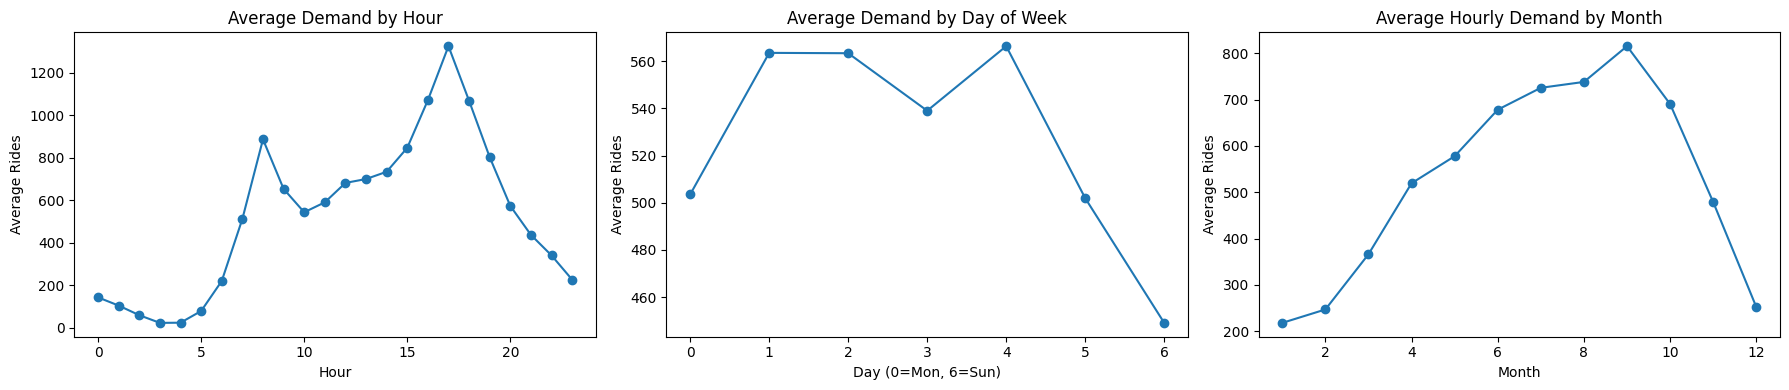

In [9]:
import matplotlib.pyplot as plt

eda_df = hourly_df.copy()
eda_df["datetime"] = pd.to_datetime(eda_df["datetime"])

# Mark daylight-saving time transition hours
dst_hours = pd.to_datetime([
    "2025-03-09 02:00:00",
    "2025-11-02 01:00:00"
])

eda_df["dst_affected"] = eda_df["datetime"].isin(dst_hours)

# Exclude DST-affected hours from descriptive averages
eda_clean = eda_df[~eda_df["dst_affected"]].copy()

# Calendar features for EDA
eda_clean["hour"] = eda_clean["datetime"].dt.hour
eda_clean["day_of_week"] = eda_clean["datetime"].dt.dayofweek
eda_clean["month"] = eda_clean["datetime"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Hourly demand pattern
eda_clean.groupby("hour")["ride_count"].mean().plot(
    ax=axes[0], marker="o"
)
axes[0].set_title("Average Demand by Hour")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Average Rides")

# Weekly demand pattern
eda_clean.groupby("day_of_week")["ride_count"].mean().plot(
    ax=axes[1], marker="o"
)
axes[1].set_title("Average Demand by Day of Week")
axes[1].set_xlabel("Day (0=Mon, 6=Sun)")
axes[1].set_ylabel("Average Rides")

# Monthly demand pattern
eda_clean.groupby("month")["ride_count"].mean().plot(
    ax=axes[2], marker="o"
)
axes[2].set_title("Average Hourly Demand by Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Average Rides")

plt.tight_layout()
plt.show()

### 5. Chronological evaluation protocol
Train: January-August; validation: September-October; held-out test: November 1-December 30. No random split of full time series. Every model makes a one-step-ahead prediction for hour t using the observed counts through t-1 (not recursive 60-day forecasting).

In [10]:
model_df = eda_df[
    eda_df["datetime"] < "2025-12-31"
].copy()

train_df = model_df[
    model_df["datetime"] < "2025-09-01"
].copy()

val_df = model_df[
    (model_df["datetime"] >= "2025-09-01")
    & (model_df["datetime"] < "2025-11-01")
].copy()

test_df = model_df[
    model_df["datetime"] >= "2025-11-01"
].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 5832
Validation: 1464
Test: 1440


### 6. AR(p)  — Geon Chang


In [11]:
import numpy as np

# Use the existing hourly demand dataset
df = hourly_df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

# DST-affected timestamps
dst_times = pd.to_datetime([
    "2025-03-09 02:00:00",
    "2025-11-02 01:00:00"
])

df["dst_affected"] = df["datetime"].isin(dst_times)

def create_ar_dataset(df, p):
    """
    Create features and targets for an AR(p) model.

    X: previous p hourly ride counts
    y: ride count at the target hour
    """

    counts = df["ride_count"].to_numpy(dtype=float)
    dates = df["datetime"].to_numpy()
    dst_flags = df["dst_affected"].to_numpy()

    X, y, timestamps = [], [], []

    for t in range(p, len(df)):

        # Exclude DST-affected targets and lag windows
        if dst_flags[t-p:t+1].any():
            continue

        # Previous p observations, most recent first
        lag_values = counts[t-p:t][::-1]

        X.append(lag_values)
        y.append(counts[t])
        timestamps.append(dates[t])

    return (
        np.asarray(X),
        np.asarray(y),
        pd.to_datetime(timestamps)
    )

print("AR dataset function ready.")

AR dataset function ready.


In [12]:
def fit_ar_model(X, y):
    """
    Fit AR(p) using ordinary least squares.
    """

    # Add intercept column
    X_bias = np.column_stack([
        np.ones(len(X)),
        X
    ])

    # Estimate regression coefficients
    coefficients, _, _, _ = np.linalg.lstsq(
        X_bias, y, rcond=None
    )

    return coefficients


def predict_ar_model(X, coefficients):

    X_bias = np.column_stack([
        np.ones(len(X)),
        X
    ])

    return X_bias @ coefficients


def evaluate_model(y_true, y_pred):

    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))

    return mae, rmse

print("AR model functions ready.")

AR model functions ready.


In [13]:
p_values = [1, 24, 168]

results = []
trained_models = {}

for p in p_values:

    X, y, dates = create_ar_dataset(df, p)

    # Chronological split
    train_mask = dates < pd.Timestamp("2025-09-01")

    val_mask = (
        (dates >= pd.Timestamp("2025-09-01"))
        & (dates < pd.Timestamp("2025-11-01"))
    )

    test_mask = (
        (dates >= pd.Timestamp("2025-11-01"))
        & (dates < pd.Timestamp("2025-12-31"))
    )

    X_train, y_train = X[train_mask], y[train_mask]
    X_val, y_val = X[val_mask], y[val_mask]

    # Train only on training data
    coefficients = fit_ar_model(X_train, y_train)

    # Evaluate on validation data
    val_pred = predict_ar_model(X_val, coefficients)

    mae, rmse = evaluate_model(y_val, val_pred)

    results.append({
        "Model": f"AR({p})",
        "Train Samples": len(X_train),
        "Validation Samples": len(X_val),
        "Validation MAE": mae,
        "Validation RMSE": rmse
    })

    trained_models[p] = coefficients

results_df = pd.DataFrame(results)

display(results_df)

,Model,Train Samples,Validation Samples,Validation MAE,Validation RMSE
0,AR(1),5829,1464,215.832642,290.843169
1,AR(24),5783,1464,124.367720,179.531628
2,AR(168),5495,1464,89.699214,133.627346


In [14]:
best_row = results_df.loc[
    results_df["Validation RMSE"].idxmin()
]

best_p = int(
    best_row["Model"]
    .replace("AR(", "")
    .replace(")", "")
)

print("Selected AR model:", f"AR({best_p})")

X, y, dates = create_ar_dataset(df, best_p)

train_val_mask = dates < pd.Timestamp("2025-11-01")

test_mask = (
    (dates >= pd.Timestamp("2025-11-01"))
    & (dates < pd.Timestamp("2025-12-31"))
)

X_train_val = X[train_val_mask]
y_train_val = y[train_val_mask]

X_test = X[test_mask]
y_test = y[test_mask]
test_dates = dates[test_mask]

# Refit using training + validation data
best_coefficients = fit_ar_model(
    X_train_val, y_train_val
)

test_predictions = predict_ar_model(
    X_test, best_coefficients
)

test_mae, test_rmse = evaluate_model(
    y_test, test_predictions
)

print(f"Test MAE:  {test_mae:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

Selected AR model: AR(168)
Test MAE:  50.80
Test RMSE: 76.72


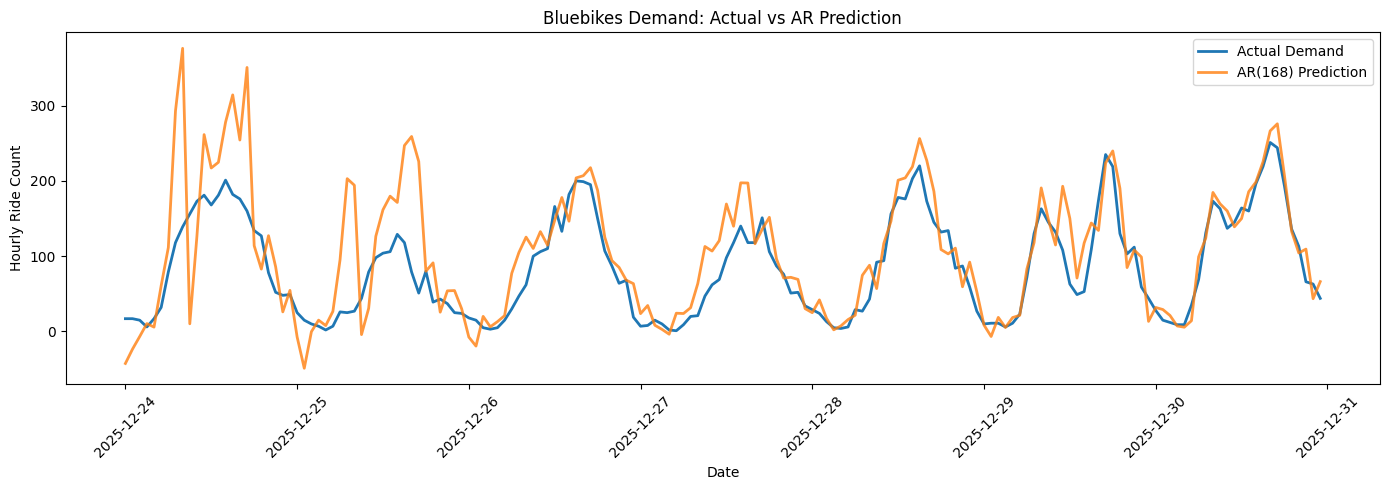

In [15]:
plt.figure(figsize=(14, 5))

last_n = 24 * 7

plt.plot(
    test_dates[-last_n:],
    y_test[-last_n:],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    test_dates[-last_n:],
    test_predictions[-last_n:],
    label=f"AR({best_p}) Prediction",
    linewidth=2,
    alpha=0.8
)

plt.title("Bluebikes Demand: Actual vs AR Prediction")
plt.xlabel("Date")
plt.ylabel("Hourly Ride Count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Validation MAE/RMSE: AR(1) 215.83 / 290.84; AR(24) 124.37 / 179.53; AR(168) 89.70 / 133.63. Selected AR(168) achieves test MAE 50.80 and RMSE 76.72.

This is evidence that richer past-hour lag information helps in this setting, but increased parameter count is a confounder. The linear model occasionally predicts negative counts and notably overshoots around holiday periods.

# 7. Bayesian linear regression — Peisong Yuan

In [16]:
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler

blr_lags, blr_y, blr_dates = create_ar_dataset(df, best_p)
blr_train = blr_dates < "2025-09-01"
blr_val = (blr_dates >= "2025-09-01") & (blr_dates < "2025-11-01")
blr_test = (blr_dates >= "2025-11-01") & (blr_dates < "2025-12-31")

hour_flags = np.eye(24)[blr_dates.hour]
weekend = np.asarray(blr_dates.dayofweek >= 5)[:, None]
blr_inputs = {
    "lags": blr_lags,
    "lags and calendar": np.column_stack([blr_lags, hour_flags, hour_flags * weekend])
}

def fit_blr(features, rows):
    scaler = StandardScaler().fit(features[rows])
    model = BayesianRidge()
    model.fit(scaler.transform(features[rows]), blr_y[rows])
    return scaler, model

blr_scores = {}
for name, features in blr_inputs.items():
    scaler, model = fit_blr(features, blr_train)
    prediction = model.predict(scaler.transform(features[blr_val]))
    mae, rmse = evaluate_model(blr_y[blr_val], prediction)
    blr_scores[name] = rmse
    print(f"{name}: validation MAE = {mae:.2f}, RMSE = {rmse:.2f}")

lags: validation MAE = 89.91, RMSE = 134.07
lags and calendar: validation MAE = 77.07, RMSE = 117.13


In [17]:
blr_choice = min(blr_scores, key=blr_scores.get)
features = blr_inputs[blr_choice]
blr_scaler, blr_model = fit_blr(features, blr_train | blr_val)
blr_pred, blr_sd = blr_model.predict(
    blr_scaler.transform(features[blr_test]), return_std=True
)
blr_actual = blr_y[blr_test]
blr_mae, blr_rmse = evaluate_model(blr_actual, blr_pred)
blr_low = blr_pred - 1.96 * blr_sd
blr_high = blr_pred + 1.96 * blr_sd
blr_coverage = np.mean((blr_actual >= blr_low) & (blr_actual <= blr_high))
print(f"Selected features: {blr_choice}")
print(f"Test hours: {len(blr_actual)}")
print(f"Test MAE: {blr_mae:.2f} rides")
print(f"Test RMSE: {blr_rmse:.2f} rides")
print(f"95% prediction interval coverage: {blr_coverage:.1%}")

Selected features: lags and calendar
Test hours: 1271
Test MAE: 52.29 rides
Test RMSE: 81.72 rides
95% prediction interval coverage: 95.6%


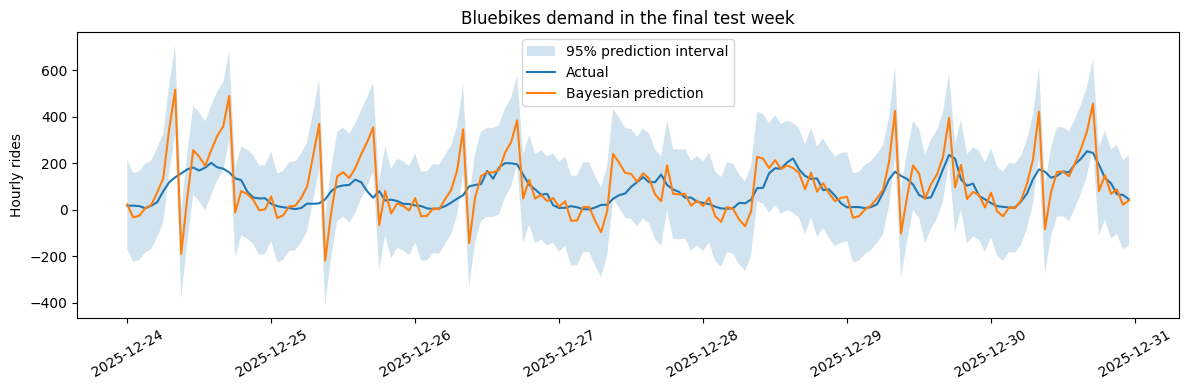

In [18]:
blr_week = blr_dates[blr_test][-168:]
plt.figure(figsize=(12, 4))
plt.fill_between(blr_week, blr_low[-168:], blr_high[-168:], alpha=0.2,
                 label="95% prediction interval")
plt.plot(blr_week, blr_actual[-168:], label="Actual")
plt.plot(blr_week, blr_pred[-168:], label="Bayesian prediction")
plt.ylabel("Hourly rides")
plt.title("Bluebikes demand in the final test week")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

Bayesian findings: Validation RMSE improves from 134.07 (lags) to 117.13 (lags + calendar). On 1,271 eligible test hours: MAE 52.29, RMSE 81.72; nominal 95% predictive interval empirical coverage 95.6%. Because hour/weekend variables were added, comparison to lag-only AR is an end-to-end pipeline comparison, not an isolated effect of Bayesian inference.

### 8. Neural network: Multi-Layer Perceptron — Miles Mu

In [19]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Reuse 168-hour lag + calendar features as the best BLR model so MLP is comparable
mlp_features = blr_inputs["lags and calendar"]

mlp_scaler = StandardScaler().fit(mlp_features[blr_train])
X_train_s = mlp_scaler.transform(mlp_features[blr_train])
X_val_s   = mlp_scaler.transform(mlp_features[blr_val])

hidden_layer_options = [(32,), (64, 32), (64, 32, 16)]

mlp_scores = {}
for hidden_layers in hidden_layer_options:
    mlp = MLPRegressor(
        hidden_layer_sizes=hidden_layers,
        activation="relu",
        solver="adam",
        alpha=1e-3,
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    )
    mlp.fit(X_train_s, blr_y[blr_train])
    val_pred = mlp.predict(X_val_s)
    mae, rmse = evaluate_model(blr_y[blr_val], val_pred)
    mlp_scores[hidden_layers] = rmse
    print(f"hidden_layers={hidden_layers}: validation MAE={mae:.2f}, RMSE={rmse:.2f}")

best_hidden = min(mlp_scores, key=mlp_scores.get)
print("\nSelected architecture:", best_hidden)

hidden_layers=(32,): validation MAE=82.98, RMSE=129.47
hidden_layers=(64, 32): validation MAE=77.22, RMSE=115.85
hidden_layers=(64, 32, 16): validation MAE=77.07, RMSE=116.19

Selected architecture: (64, 32)


In [20]:
# Refit then evaluate once on the held-out test set
train_val_mask = blr_train | blr_val

mlp_scaler = StandardScaler().fit(mlp_features[train_val_mask])
X_trval_s = mlp_scaler.transform(mlp_features[train_val_mask])
X_test_s  = mlp_scaler.transform(mlp_features[blr_test])

mlp_model = MLPRegressor(
    hidden_layer_sizes=best_hidden,
    activation="relu",
    solver="adam",
    alpha=1e-3,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=42
)
mlp_model.fit(X_trval_s, blr_y[train_val_mask])

mlp_pred = mlp_model.predict(X_test_s)
mlp_actual = blr_y[blr_test]
mlp_mae, mlp_rmse = evaluate_model(mlp_actual, mlp_pred)

print(f"Test MAE:  {mlp_mae:.2f}")
print(f"Test RMSE: {mlp_rmse:.2f}")
print(f"Training stopped after {mlp_model.n_iter_} iterations (early stopping)")

Test MAE:  43.43
Test RMSE: 62.19
Training stopped after 241 iterations (early stopping)


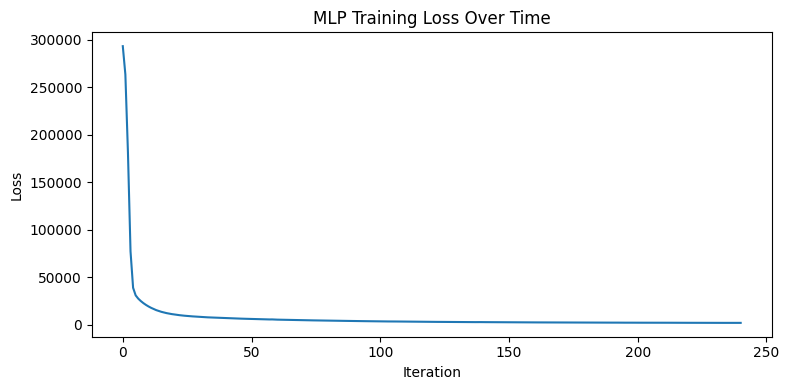

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(mlp_model.loss_curve_)
plt.title("MLP Training Loss Over Time")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

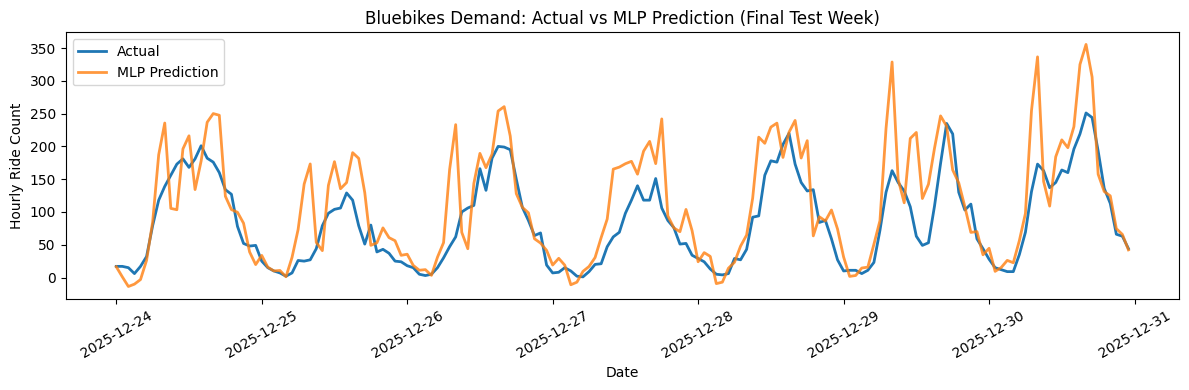

In [22]:
mlp_week_dates = blr_dates[blr_test][-168:]

plt.figure(figsize=(12, 4))
plt.plot(mlp_week_dates, mlp_actual[-168:], label="Actual", linewidth=2)
plt.plot(mlp_week_dates, mlp_pred[-168:], label="MLP Prediction", linewidth=2, alpha=0.8)
plt.title("Bluebikes Demand: Actual vs MLP Prediction (Final Test Week)")
plt.xlabel("Date")
plt.ylabel("Hourly Ride Count")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

MLP findings:
Selected architecture (64, 32). Validation MAE 77.22, RMSE 115.85; test MAE 43.43, RMSE 62.19. The lower errors suggest the MLP pipeline was the strongest of the three as implemented. The current experiment does not isolate nonlinear modeling from the benefit of calendar features over lag-only AR.

### 9. Final alignment, baseline, and fair-comparison audit
Run the following additional cells after all three models. They check that results use identical timestamps and targets, calculate a weekly seasonal-naive benchmark, and summarize saved model scores. If this check fails, do not compare the printed results until the timestamps are aligned.

In [23]:
# All selected models must evaluate identical hours and actual counts.
assert np.array_equal(np.asarray(test_dates), np.asarray(blr_dates[blr_test]))
assert np.array_equal(y_test, blr_actual)
assert np.array_equal(y_test, mlp_actual)
print('PASS: AR, Bayesian, and MLP test targets/timestamps match:', len(y_test))

# Seasonal naive: predict current hourly count from the exact same clock hour 7 days ago.
# create_ar_dataset returns columns [t-1, t-2, ..., t-168].
assert best_p == 168
weekly_naive = X_test[:, 167]
naive_mae, naive_rmse = evaluate_model(y_test, weekly_naive)
print(f'Seasonal naive baseline: MAE={naive_mae:.2f}, RMSE={naive_rmse:.2f}')

comparison = pd.DataFrame([
    {'Method':'Seasonal naive (t-168)', 'MAE':naive_mae, 'RMSE':naive_rmse},
    {'Method':'AR(168) (lags only)', 'MAE':test_mae, 'RMSE':test_rmse},
    {'Method':'Bayesian Ridge (lags+calendar)', 'MAE':blr_mae, 'RMSE':blr_rmse},
    {'Method':'MLP (lags+calendar)', 'MAE':mlp_mae, 'RMSE':mlp_rmse},
]).sort_values('RMSE')
display(comparison)

print('Test date range:',test_dates.min(), 'to', test_dates.max())
print('Best RMSE model:',comparison.iloc[0]['Method'])

PASS: AR, Bayesian, and MLP test targets/timestamps match: 1271
Seasonal naive baseline: MAE=127.58, RMSE=205.07


,Method,MAE,RMSE
3,MLP (lags+calendar),43.429752,62.185391
1,AR(168) (lags only),50.802133,76.724193
2,Bayesian Ridge (lags+calendar),52.294436,81.715243
0,Seasonal naive (t-168),127.582219,205.073430


Test date range: 2025-11-01 00:00:00 to 2025-12-30 23:00:00
Best RMSE model: MLP (lags+calendar)


In [24]:
# AR(168): largest absolute lag coefficients
ar_coefficients = pd.DataFrame({
    "Lag": np.arange(1, best_p + 1),
    "Coefficient": best_coefficients[1:]
})

ar_coefficients["Absolute"] = (
    ar_coefficients["Coefficient"].abs()
)

print("AR intercept:", best_coefficients[0])

display(
    ar_coefficients
    .sort_values("Absolute", ascending=False)
    .head(10)
)

# Bayesian Ridge: standardized feature coefficients
feature_names = (
    [f"lag_{i}" for i in range(1, 169)]
    + [f"hour_{h}" for h in range(24)]
    + [f"weekend_hour_{h}" for h in range(24)]
)

bayesian_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": blr_model.coef_
})

bayesian_coefficients["Absolute"] = (
    bayesian_coefficients["Coefficient"].abs()
)

display(
    bayesian_coefficients
    .sort_values("Absolute", ascending=False)
    .head(10)
)

AR intercept: 6.5355624721278405


,Lag,Coefficient,Absolute
0,1,0.976501,0.976501
24,25,-0.366527,0.366527
23,24,0.356300,0.356300
144,145,-0.340763,0.340763
143,144,0.294709,0.294709
1,2,-0.210297,0.210297
9,10,-0.153912,0.153912
8,9,0.143244,0.143244
158,159,0.101229,0.101229
166,167,0.096211,0.096211


,Feature,Coefficient,Absolute
0,lag_1,510.076063,510.076063
1,lag_2,-80.712809,80.712809
24,lag_25,-80.708359,80.708359
23,lag_24,77.913550,77.913550
144,lag_145,-64.738298,64.738298
119,lag_120,55.760286,55.760286
177,hour_9,-53.754463,53.754463
176,hour_8,50.281042,50.281042
143,lag_144,48.678232,48.678232
120,lag_121,-48.600253,48.600253


### 10. Findings, Limitations, and Next Steps

- Main Finding: MLP (64,32) achieved the best test performance (MAE: 43.43, RMSE: 62.19). However, MLP and Bayesian Regression used additional calendar features, so the comparison is not entirely controlled.

- Limitations: Predictions are one-step-ahead, DST-affected hours were excluded, and the dataset covers only 2025. Weather, holidays, and special events were not considered. Models may also produce negative predictions.

- Next Steps: Compare models using identical features, analyze holiday errors, and improve MLP validation. Finalize the Phase I report and ensure reproducibility.